# CASALS to 3DEP: physical vertical transformation and closure

## 1. Objective and reference systems

Convert CASALS ellipsoidal coordinates toward the documented NAVD88 target and assess closure using independent 3DEP evaluation. No parameter is estimated from CASALS-minus-3DEP residuals. Historical results and the [preserved audit](elevation_reference_audit.ipynb) remain unchanged.

| Item | CASALS source | Required 3DEP target | Evidence status |
|---|---|---|---|
| Height | WGS84 ellipsoidal Refh | NAVD88 orthometric height | Meeting convention / audited 3DEP metadata |
| Geoid | EGM2008 tide-free provided in L1B | GEOID18 | Official model identities |
| Realization | Specific WGS84 / ITRF / IGS realization unknown | NAD83(2011), GRS80 | Source unverified |
| Coordinate epoch | Unknown (flight date used in hypotheses) | 2010.0 for GEOID18 input | Explicit hypotheses H1-H4 in Section 3b; not verified |
| Additional corrections | Per-field sign and applied state unresolved | Traceable physical chain required | None additionally applied |

Sources: [2026-10-15 meeting](../../../docs/meeting/20261015_140029.txt), [3DEP provenance audit](../../../docs/casals_l1b_validation_report.md), [NOAA GEOID18 requirements](https://geodesy.noaa.gov/GEOID/GEOID18/geoid18_tech_details.shtml). The Maryland generic XML geoid conflict remains documented; final product evidence supports GEOID18 for both audited references.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='Best transformation is not available', category=UserWarning)
from pathlib import Path
from datetime import datetime, timezone
import os
import sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'casals_l1b').is_dir()
sys.path.insert(0, str(ROOT))
from research.reference.vertical_alignment import run_alignment, plot_results
RUN_ID = os.environ.get('CASALS_RUN_ID') or datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = ROOT / 'outputs/notebooks/geolocation/vertical_datum_alignment/runs' / RUN_ID
if RUN_DIR.exists():
    raise FileExistsError(f'Run output already exists; choose a new CASALS_RUN_ID: {RUN_DIR}')
R = run_alignment(RUN_DIR)
print('New output:', RUN_DIR.relative_to(ROOT))

[nptdms.tdms_segment WARNING] Data size 17582522368 is not a multiple of the chunk size 1441792. Will attempt to read last chunk


Processing casals_l1b_20241112T165718_001_02: physical heights, then class-2 reference


Processing casals_l1b_20241118T171757_001_02: physical heights, then class-2 reference


New output: outputs\notebooks\geolocation\vertical_datum_alignment\runs\20261017T015011000000Z


## 2. Source height and correction audit

The current H5 root attributes, all twelve scalar fields below, and metadata from both local TDMS files are reread. Every correction's complete definition, units, affected physical quantity, sign, applied state, expected effect, and current action are recorded in `physical_correction_audit.csv`. The tables distinguish the confirmed input/model from unresolved processing contracts.

`casals_epoch_*` and `delta_time` define observation-time bookkeeping from 2018-01-01; this is not a navigation coordinate epoch. H5 references GPS CSV, geolocation, L1A/ARD and TDMS files whose exact basenames are absent locally. The available TDMS files contain timing/scan properties and no navigation realization or epoch, and do not match the H5 upstream basenames. The [NASA system paper](https://ntrs.nasa.gov/api/citations/20240001267/downloads/Conference%20Paper.pdf) identifies POS 510 hardware, not the frame or processing state of these granules.

Neutral atmospheric optical path, one-/two-way travel time, slant range, and vertical height are different quantities. For a confirmed omitted positive excess range, the first-order height effect would be `delta_h = -delta_range * dot(beam_sensor_to_target, local_up)`. Its use would require a confirmed range equation, units, beam convention, sign, and unapplied status. Those conditions are not established; the stored 1-1.6 numeric delay is not applied. Zero range bias is not proof of an applied zero calibration. Tide terms are not summed or sign-tested as formal transformations.

In [2]:
audit = R['corrections']
display(audit.drop_duplicates('field')[['field', 'official_definition', 'units', 'acts_on',
    'sign_convention', 'applied_to_refh', 'current_action']].reset_index(drop=True))
display(Markdown('**Current full-granule numeric medians (undeclared H5 units remain undeclared)**'))
display(audit.pivot(index='field', columns='granule_id', values='median_numeric').round(6))
assert not audit.eligible_for_additional_correction.any()

,field,official_definition,units,acts_on,sign_convention,applied_to_refh,current_action
0,refh,WGS84 ellipsoidal reference-return height (mee...,m (product convention; H5 undeclared),ellipsoidal height,UNKNOWN,input; not an extra correction,input height
1,geoid,"EGM2008 tide-free geoid height (Jeff Lee, meet...",m (NGA numerical validation),geoid height,H_EGM = h - N_EGM,UNKNOWN,EGM2008 diagnostic only
2,geoid_free2mean,Mean-tide geoid conversion provided (meeting);...,UNKNOWN,geoid height; complete height chain unknown,UNKNOWN,UNKNOWN,not applied
3,refh_neutat_delay_total,UNKNOWN: no per-field official processing cont...,UNKNOWN,neutral atmosphere optical path/range/time: ex...,UNKNOWN,UNKNOWN,not applied
4,refh_neutat_delay_derivative,UNKNOWN: no per-field official processing cont...,UNKNOWN,delay derivative; independent/dependent units ...,UNKNOWN,UNKNOWN,not applied
5,range_bias_correction,UNKNOWN: no per-field official processing cont...,UNKNOWN,range (field name only; official definition un...,UNKNOWN,UNKNOWN,not applied
6,tide_earth,UNKNOWN: no per-field official processing cont...,UNKNOWN,solid-Earth/load/ocean/pole/permanent-tide ter...,UNKNOWN,UNKNOWN,not applied
7,tide_earth_free2mean,UNKNOWN: no per-field official processing cont...,UNKNOWN,solid-Earth/load/ocean/pole/permanent-tide ter...,UNKNOWN,UNKNOWN,not applied
8,tide_load,UNKNOWN: no per-field official processing cont...,UNKNOWN,solid-Earth/load/ocean/pole/permanent-tide ter...,UNKNOWN,UNKNOWN,not applied
9,tide_ocean,UNKNOWN: no per-field official processing cont...,UNKNOWN,solid-Earth/load/ocean/pole/permanent-tide ter...,UNKNOWN,UNKNOWN,not applied


**Current full-granule numeric medians (undeclared H5 units remain undeclared)**

granule_id,casals_l1b_20241112T165718_001_02,casals_l1b_20241118T171757_001_02
field,,
geoid,-36.832462,-37.431847
geoid_free2mean,-0.019859,-0.005459
range_bias_correction,0.000000,0.000000
refh,-25.504444,-32.380623
refh_neutat_delay_derivative,0.000278,0.000278
refh_neutat_delay_total,1.593985,1.180952
tide_earth,-0.015728,-0.075044
tide_earth_free2mean,-0.009538,-0.002770
tide_load,0.006266,0.001652


## 3. Reference-frame and Coordinate-Epoch Assessment

The physical-only C7 result above is preserved as H0: its existing EPSG:4979 to EPSG:6319 frame step is a no-op. H1-H3 below are conditional 3D source-frame hypotheses, evaluated with the installed EPSG operations and followed by the same pinned GEOID18 route. They are diagnostics; they do not replace the H0 physical baseline or identify the CASALS navigation frame.

A time-dependent Helmert evaluated with a fourth-coordinate time applies the frame operation at that parameter time. PROJ preserves that coordinate time; the operation's parameter reference epoch is not the target coordinate epoch. Full coordinate-epoch propagation is a separate step requiring a velocity/deformation model. The NGS HTDP check below reports same-epoch frame conversion separately from its ITRF2014-assumption propagation to NAD83(2011), epoch 2010.0. See the [PROJ time-dependent operation](https://proj.org/en/stable/operations/time_dependent_transformations.html), [PROJ Helmert reference](https://proj.org/en/stable/operations/transformations/helmert.html), and [NGS HTDP guide](https://geodesy.noaa.gov/TOOLS/Htdp/HTDP-user-guide.pdf).


In [3]:
frame_columns = ['granule_id', 'source_frame', 'source_realization', 'source_coordinate_epoch',
    'target_frame', 'required_target_coordinate_epoch', 'target_coordinate_epoch_achieved',
    'is_noop', 'is_ballpark', 'accuracy_metadata_m', 'delta_longitude_deg_max_abs',
    'delta_latitude_deg_max_abs', 'delta_ellipsoidal_height_m_median', 'delta_ellipsoidal_height_m_max_abs']
display(R['frame'][frame_columns])
for gid, op in R['operations']['granules'].items():
    display(Markdown('**' + gid + ': actual combined operation**' + chr(10) + '```text' + chr(10) + op['combined_operation'] + chr(10) + '```'))
samples = R['population'].groupby('granule_id', sort=True).head(1)
display(samples[['granule_id', 'pulse_index', 'longitude_deg', 'latitude_deg', 'Native_height_m',
    'frame_longitude_deg', 'frame_latitude_deg', 'frame_ellipsoidal_height_m',
    'frame_delta_longitude_deg', 'frame_delta_latitude_deg', 'frame_delta_ellipsoidal_height_m']])

,granule_id,source_frame,source_realization,source_coordinate_epoch,target_frame,required_target_coordinate_epoch,target_coordinate_epoch_achieved,is_noop,is_ballpark,accuracy_metadata_m,delta_longitude_deg_max_abs,delta_latitude_deg_max_abs,delta_ellipsoidal_height_m_median,delta_ellipsoidal_height_m_max_abs
0,casals_l1b_20241112T165718_001_02,WGS84 ensemble (EPSG:4979),None,None,NAD83(2011) (EPSG:6319),2010.0,None,True,False,2.0,0.0,0.0,0.0,0.0
1,casals_l1b_20241118T171757_001_02,WGS84 ensemble (EPSG:4979),None,None,NAD83(2011) (EPSG:6319),2010.0,None,True,False,2.0,0.0,0.0,0.0,0.0


**casals_l1b_20241112T165718_001_02: actual combined operation**
```text
proj=pipeline step proj=unitconvert xy_in=deg xy_out=rad step inv proj=vgridshift grids=us_noaa_g2018u0.tif multiplier=1 step proj=utm zone=18 ellps=GRS80
```

**casals_l1b_20241118T171757_001_02: actual combined operation**
```text
proj=pipeline step proj=unitconvert xy_in=deg xy_out=rad step inv proj=vgridshift grids=us_noaa_g2018u0.tif multiplier=1 step proj=utm zone=18 ellps=GRS80
```

,granule_id,pulse_index,longitude_deg,latitude_deg,Native_height_m,frame_longitude_deg,frame_latitude_deg,frame_ellipsoidal_height_m,frame_delta_longitude_deg,frame_delta_latitude_deg,frame_delta_ellipsoidal_height_m
0,casals_l1b_20241112T165718_001_02,1040402,-75.281099,38.410052,-166.092717,-75.281099,38.410052,-166.092717,0.0,0.0,0.0
36276,casals_l1b_20241118T171757_001_02,2821855,-76.695553,36.189333,-33.406726,-76.695553,36.189333,-33.406726,0.0,0.0,0.0


### Conditional source-frame hypotheses and common-sample evaluation

| Hypothesis | Explicit source CRS | Evaluation / coordinate-time input | Interpretation |
|---|---|---|---|
| H0 | Existing EPSG:4979 WGS84 ensemble | Existing no-op route | Preserved physical-only C7 baseline; source frame remains unknown |
| H1 | WGS84 (G2296), EPSG:10605 | Flight timestamp, assumed conditionally | G2296-to-ITRF2020 EPSG step followed by the time-dependent ITRF2020-to-NAD83(2011) operation |
| H2 | ITRF2014, EPSG:7912 | Flight timestamp, assumed conditionally | Time-dependent ITRF2014-to-NAD83(2011) operation |
| H3 | ITRF2020, EPSG:9989 | Flight timestamp, assumed conditionally | Time-dependent ITRF2020-to-NAD83(2011) operation |
| H4 | ITRF2014, EPSG:7912 | 2010.0 supplied for sensitivity | Parameter-time sensitivity only; not coordinate-epoch propagation |

The source CRS dimension, ellipsoid, frame name, dynamic/static type, and frame reference epoch are read from the installed EPSG database. Each selected non-ballpark operation, full transformation chain, Helmert parameters and rates, rotation convention, parameter reference epoch, authority, and area of use is saved in `frame_hypothesis_operations.json`. The installed operations are applied only when their best operation is available and covers the full input extent; no ensemble, no-op, or alternate-frame fallback is used. A 3D inverse round trip checks numerical reversibility, while an independent ITRF2014 geocentric XYZ checkpoint checks the operation direction and metre units.

The flight timestamp is used as a conditional coordinate-time input for H1-H3; it is not evidence that the stored Refh coordinates have that coordinate epoch. For every route, the report records the frame reference epoch, assumed coordinate time, Helmert parameter reference epoch, output coordinate time, required target coordinate epoch, and whether propagation was applied. H4 changes the Helmert evaluation time while retaining the original coordinate values. It is not labelled a valid 2010.0 coordinate result.

Every hypothesis reuses the frozen field/road pulse membership and independently queries the 3DEP surface at its transformed horizontal coordinates. The tables below report each method's own valid coverage and a separate intersection using the same exact pulse IDs for every available method. Per-pulse common IDs and SHA-256 hashes are saved under `frame_hypotheses/`; the transformation decomposition is checked pulse-by-pulse as `delta_residual = delta_H - delta_reference`.


In [4]:
import os
from research.reference.frame_hypotheses import run_frame_hypotheses, block_bootstrap_bias, vdatum_itrf_check
from research.reference.htdp_crosscheck import run_htdp_checkpoints
from research.reference.geodetic_crosscheck import run_transformed_checkpoint_crosscheck

F = run_frame_hypotheses(R, RUN_DIR / 'frame_hypotheses')
operation_columns = ['granule_id', 'hypothesis', 'source_epsg', 'operation_status',
    'operation_authority', 'helmert_parameter_reference_epoch', 'area_contains_input_extent',
    'coordinate_epoch_propagation_applied', 'target_coordinate_epoch_achieved']
display(Markdown('**Selected frame-operation audit**'))
display(F['source_crs'][[c for c in operation_columns if c in F['source_crs']]].fillna('').to_string(index=False))
display(Markdown('**Frame-induced ellipsoidal, NAVD88-diagnostic, query-position and reference-height changes from H0 (metres)**'))
display(F['shifts'].round(4))
display(Markdown('**Per-method field-test coverage, SNR >= 5**'))
display(F['coverage'].query("population == 'field' and stratum == 'snr_ge_5'"))
display(Markdown('**Common-pulse field-test metrics, SNR >= 5; exact IDs and hashes are in frame_hypothesis_common_pulses.csv**'))
primary_common = F['metrics'].query("population == 'field' and stratum == 'snr_ge_5'")
common_columns = ['granule_id', 'hypothesis', 'n', 'coverage', 'pulse_sha256',
    'mean_bias_m', 'median_bias_m', 'RMSE_m', 'cRMSE_m', 'NMAD_m', 'absolute_P95_m']
display(primary_common[common_columns].round(4))
display(Markdown('**Fixed-point PROJ / official NGS HTDP verification (pulse_index=0 in each granule)**'))
T = run_htdp_checkpoints(R, RUN_DIR / 'htdp_crosscheck', os.environ.get('CASALS_HTDP_EXE'))
display(Markdown('HTDP status: `' + T['status']['status'] + '`'))
XT = None
if T['status']['status'] == 'completed':
    display(T['same_epoch'][['granule_id', 'source_frame', 'input_epoch', 'output_epoch',
        'PROJ_minus_HTDP_horizontal_m', 'PROJ_minus_HTDP_height_m']].round(6))
    display(Markdown('**ITRF2014-assumption NAD83(2011) observation-epoch to 2010.0 propagation (HTDP model)**'))
    display(T['epoch_propagation'][['granule_id', 'source_coordinate_epoch_assumption',
        'target_coordinate_epoch', 'B_to_C_horizontal_displacement_m',
        'B_to_C_ellipsoidal_height_change_m']].round(6))
    XT = run_transformed_checkpoint_crosscheck(
        T['points_2010'], RUN_DIR / 'htdp_crosscheck' / 'geoid18_software_check', project_root=ROOT)
    display(Markdown('**Pinned GEOID18/NGS/VDatum numerical check at those two propagated points**'))
    display(XT['checkpoints'][['granule_id', 'H_PROJ_m', 'H_NGS_m', 'H_VDATUM_m',
        'PROJ_minus_NGS_height_m', 'PROJ_minus_VDatum_m', 'NGS_status', 'VDatum_status']].round(6))
    display(Markdown('HTDP-checkpoint software status: `' + XT['status']['status'] + '`'))
else:
    display(Markdown('HTDP was not run. No fixed-point output is inferred; configure `CASALS_HTDP_EXE` to enable it.'))


**Selected frame-operation audit**

"                       granule_id                                  hypothesis operation_status                  operation_authority  helmert_parameter_reference_epoch  area_contains_input_extent  coordinate_epoch_propagation_applied  target_coordinate_epoch_achieved\ncasals_l1b_20241112T165718_001_02                    H1_WGS84_G2296_obs_epoch        available {'authority': 'EPSG', 'code': 10334}                             2010.0                        True                                 False                             False\ncasals_l1b_20241112T165718_001_02                       H2_ITRF2014_obs_epoch        available  {'authority': 'EPSG', 'code': 8970}                             2010.0                        True                                 False                             False\ncasals_l1b_20241112T165718_001_02                       H3_ITRF2020_obs_epoch        available {'authority': 'EPSG', 'code': 10334}                             2010.0                        True 

**Frame-induced ellipsoidal, NAVD88-diagnostic, query-position and reference-height changes from H0 (metres)**

,granule_id,hypothesis,population,n_paired,pulse_sha256,median_delta_h_ellipsoidal_m,median_delta_H_NAVD88_diagnostic_m,median_horizontal_query_displacement_m,median_delta_reference_height_m,median_delta_residual_m
0,casals_l1b_20241112T165718_001_02,H1_WGS84_G2296_obs_epoch,field,14477,0df12725ea0569feec9d0ebf0ab63859be43cd8675e9bc...,1.3050,1.3050,1.1774,0.0038,1.3012
1,casals_l1b_20241112T165718_001_02,H1_WGS84_G2296_obs_epoch,road,9,92d9c26d646557a6c98444cfa66e30fe8e8f0e9ba6f205...,1.3049,1.3049,1.1775,0.0221,1.2827
2,casals_l1b_20241112T165718_001_02,H2_ITRF2014_obs_epoch,field,14476,b0a42dd0bb7c3479c590f7e6b42a1fc233ae36ca618ada...,1.3043,1.3044,1.1800,0.0038,1.3006
3,casals_l1b_20241112T165718_001_02,H2_ITRF2014_obs_epoch,road,9,92d9c26d646557a6c98444cfa66e30fe8e8f0e9ba6f205...,1.3042,1.3043,1.1800,0.0222,1.2821
4,casals_l1b_20241112T165718_001_02,H3_ITRF2020_obs_epoch,field,14477,0df12725ea0569feec9d0ebf0ab63859be43cd8675e9bc...,1.3049,1.3049,1.1775,0.0038,1.3012
5,casals_l1b_20241112T165718_001_02,H3_ITRF2020_obs_epoch,road,9,92d9c26d646557a6c98444cfa66e30fe8e8f0e9ba6f205...,1.3048,1.3048,1.1776,0.0221,1.2827
6,casals_l1b_20241112T165718_001_02,H4_ITRF2014_parameter_time_sensitivity_2010,field,14505,0b65704e5323c3cb4ed7f146635ac75189ffa0b3c6de25...,1.3156,1.3156,1.0002,0.0030,1.3126
7,casals_l1b_20241112T165718_001_02,H4_ITRF2014_parameter_time_sensitivity_2010,road,11,8f932b4f6886d450278265e8e43d2a1cc239b0f9d262d8...,1.3155,1.3155,1.0003,0.0256,1.2899
8,casals_l1b_20241118T171757_001_02,H1_WGS84_G2296_obs_epoch,field,8924,eec022a9f3e7ca01aada20b1e7a074f039908039e33b73...,1.3613,1.3613,1.1244,0.0024,1.3589
9,casals_l1b_20241118T171757_001_02,H1_WGS84_G2296_obs_epoch,road,165,e575da0e4d485c7f1a16545a2b0fc457a60f7086cd3a2c...,1.3613,1.3613,1.1243,0.0409,1.3204


**Per-method field-test coverage, SNR >= 5**

...

**ITRF2014-assumption NAD83(2011) observation-epoch to 2010.0 propagation (HTDP model)**

,granule_id,source_coordinate_epoch_assumption,target_coordinate_epoch,B_to_C_horizontal_displacement_m,B_to_C_ellipsoidal_height_change_m
0,casals_l1b_20241112T165718_001_02,2024.865318,2010.0,0.032809,0.013
1,casals_l1b_20241118T171757_001_02,2024.881751,2010.0,0.031209,0.012


**Pinned GEOID18/NGS/VDatum numerical check at those two propagated points**

,granule_id,H_PROJ_m,H_NGS_m,H_VDATUM_m,PROJ_minus_NGS_height_m,PROJ_minus_VDatum_m,NGS_status,VDatum_status
0,casals_l1b_20241112T165718_001_02,25.060157,25.060,25.060,0.000157,0.000157,success,success
1,casals_l1b_20241118T171757_001_02,4.393826,4.394,4.394,-0.000174,-0.000174,success,success


HTDP-checkpoint software status: `PASSED`

## 3c. Independent verification of the frame step (NOAA VDatum)

NOAA VDatum (HTDP-based, an implementation independent of PROJ/EPSG) converts the frozen 20 pulses per granule from ITRF2014 at the flight epoch to NAD83(2011) epoch 2010.0 (HTDP propagation included) and NAVD88 (GEOID18). Its NAVD88 height is compared with the H2 PROJ pipeline above, which applies the frame Helmert only and does not propagate to 2010.0; the difference therefore includes the small propagation term quantified by the HTDP checkpoint in Section 3. VDatum uncertainty is reported by the service (about 0.06 m for the vertical datum conversion) and rounds heights to 1 mm. Failed requests are kept as failures.

In [5]:
V = vdatum_itrf_check(RUN_DIR / 'vdatum_itrf2014')
display(Markdown('**Table 3c-1 - H2 (ITRF2014 @ flight epoch) NAVD88 height: PROJ minus VDatum; metres**'))
display(V['summary'].round(4))

**Table 3c-1 - H2 (ITRF2014 @ flight epoch) NAVD88 height: PROJ minus VDatum; metres**

,granule_id,successful,mean_m,median_m,max_abs_m,requested
0,casals_l1b_20241112T165718_001_02,20,-0.0153,-0.0153,0.0157,20
1,casals_l1b_20241118T171757_001_02,20,-0.0137,-0.0137,0.0139,20


## 4. Physical vertical transformation

The three physical calculations remain `Native = refh`, `EGM2008 = refh - geoid`, and the existing **H0** C7 GEOID18 operation. H0 remains provisional because its source-frame step is a no-op and the CASALS realization/coordinate epoch is unknown. H1-H4 are isolated conditional diagnostics that rerun the same GEOID18 operation after their stated frame-coordinate hypotheses; they do not rewrite the saved H0 population or historical baseline.

The strict target equation is `H_NAVD88 = h_NAD83(2011),2010.0 - N_GEOID18`. All H0 and new NAD83 routes require the same local `us_noaa_g2018u0.tif` grid and pinned SHA-256 `fa9a407ac7ee3f5a3694008e4bcd09ce9cc250452f0c3b11700a4960340abce2`; an independent four-cell rasterio interpolation checks sign and numerical height. This verifies the selected numerical operation and grid, not the source-frame assumption or the physical application of any CASALS correction field.


In [6]:
point_rows = []
for gid, op in R['operations']['granules'].items():
    point_rows.append({'granule_id': gid, **op['independent_grid_point'],
        'median_total_vertical_change_m': op['median_total_vertical_change_m']})
display(pd.DataFrame(point_rows)[['granule_id', 'longitude_deg', 'latitude_deg',
    'assumed_NAD83_ellipsoidal_h_m', 'N_GEOID18_m', 'independently_computed_H_m',
    'PROJ_H_m', 'difference_m', 'median_total_vertical_change_m']].round(8))
display(Markdown('**EGM2008 historical numeric consistency (1,200 unchanged coordinates per granule)**'))
display(R['geoid'].round(8))
display(Markdown('**C7 height, reference-plane and pulse-set parity**'))
display(R['parity'].round(12))

,granule_id,longitude_deg,latitude_deg,assumed_NAD83_ellipsoidal_h_m,N_GEOID18_m,independently_computed_H_m,PROJ_H_m,difference_m,median_total_vertical_change_m
0,casals_l1b_20241112T165718_001_02,-75.281099,38.410052,-166.092717,-35.902558,-130.190159,-130.190159,0.0,35.898677
1,casals_l1b_20241118T171757_001_02,-76.695553,36.189333,-33.406726,-36.385140,2.978414,2.978414,-0.0,36.368041


**EGM2008 historical numeric consistency (1,200 unchanged coordinates per granule)**

,granule_id,n,H5_minus_NGA_EGM2008_median_m,max_abs_m
0,casals_l1b_20241112T165718_001_02,1200,0.000438,0.000984
1,casals_l1b_20241118T171757_001_02,1200,-0.002074,0.002750


**C7 height, reference-plane and pulse-set parity**

,granule_id,population,n,pulse_sha256,max_height_difference_m,max_reference_difference_m
0,casals_l1b_20241112T165718_001_02,field,32859,92e256f3e8eb312b13ef1db5766c8935f721789bc24e75...,0.0,0.0
1,casals_l1b_20241112T165718_001_02,road,147,061792665502668adf77da09a6371f3bc8cd17d3e4e2d9...,0.0,0.0
2,casals_l1b_20241118T171757_001_02,field,16064,42dd484170417cd1165062570145263e3f0994c9b47e4a...,0.0,0.0
3,casals_l1b_20241118T171757_001_02,road,165,e575da0e4d485c7f1a16545a2b0fc457a60f7086cd3a2c...,0.0,0.0


### Preserved H0 physical-baseline diagnostics

These figures retain the existing physical-only H0 distributions and GEOID18 spatial residuals. The H0/H2 common-pulse comparison figures appear in Section 6.

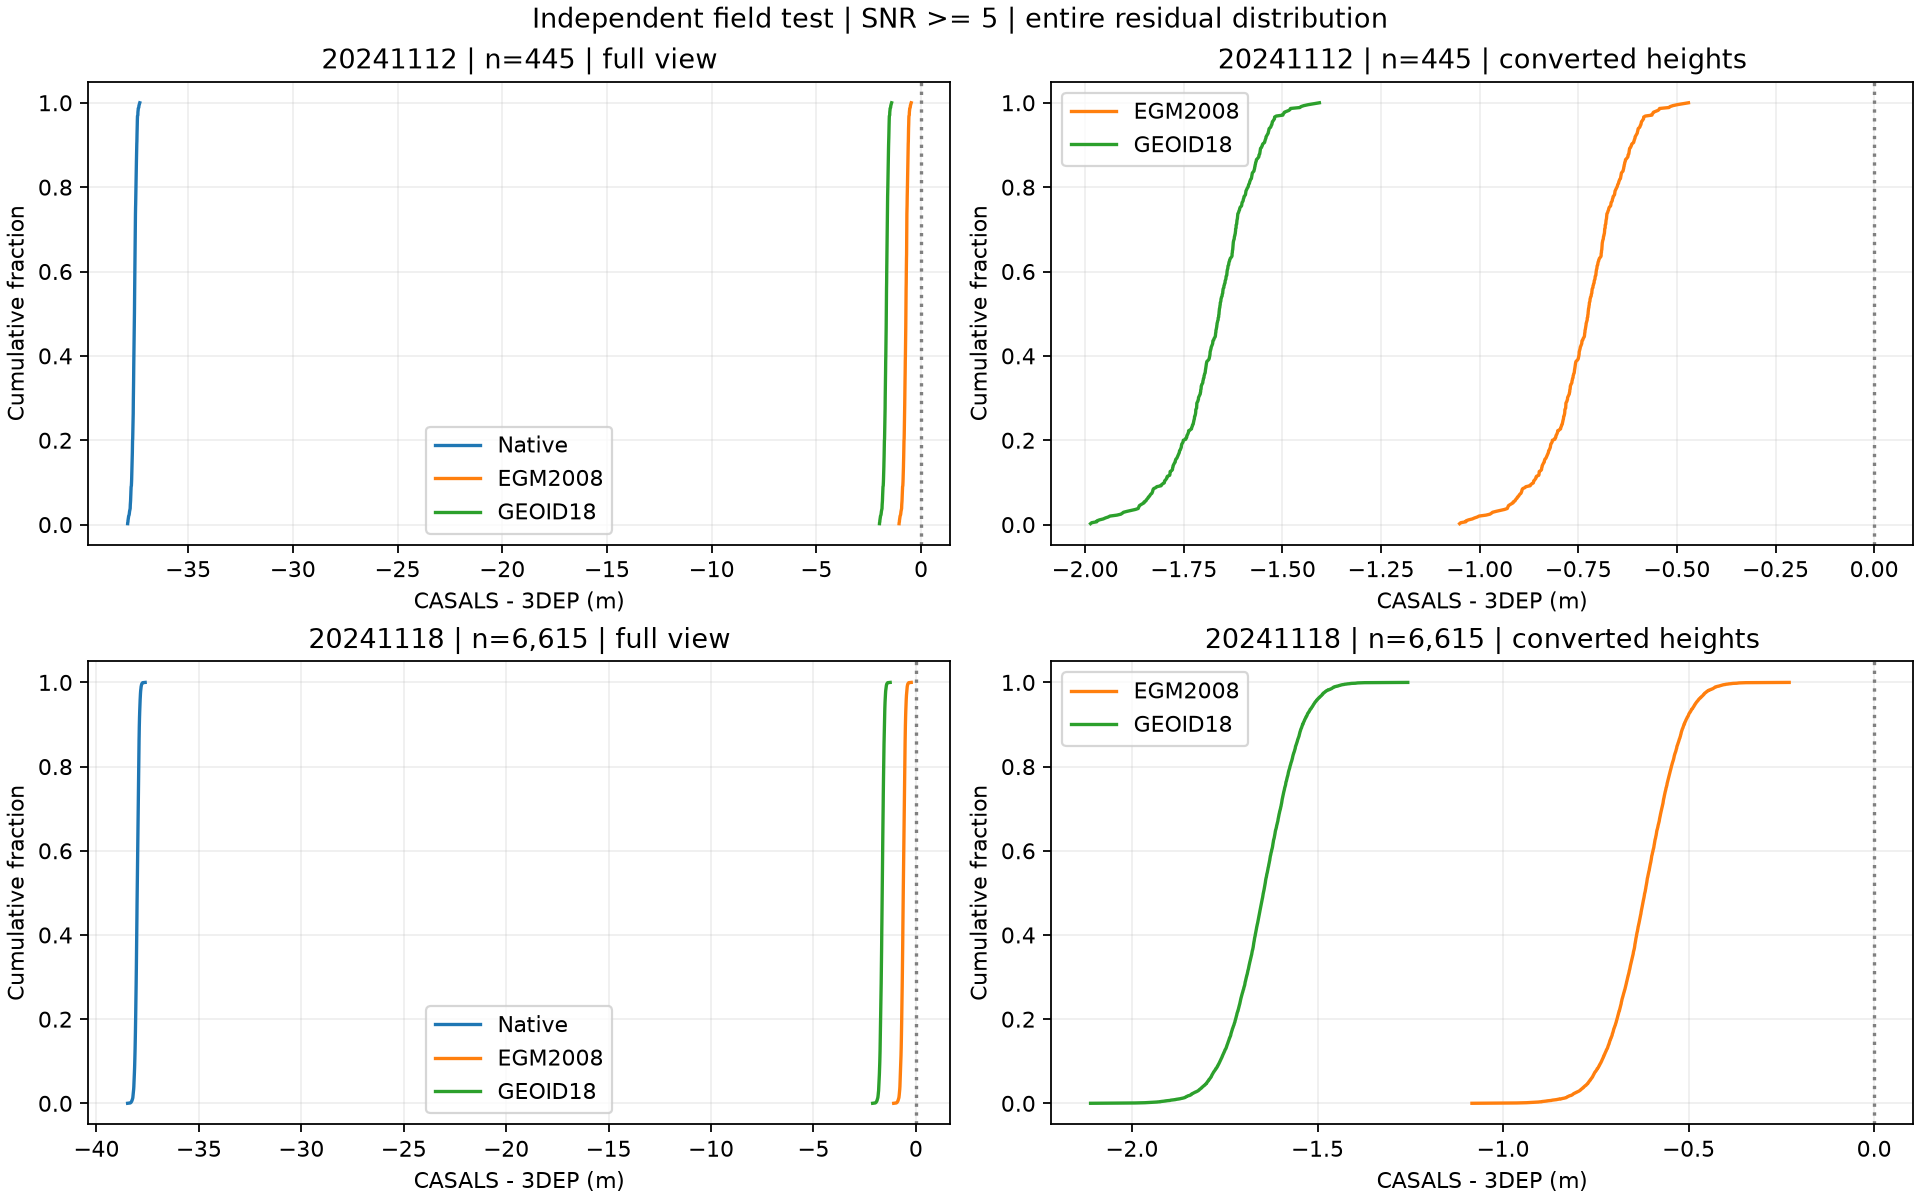

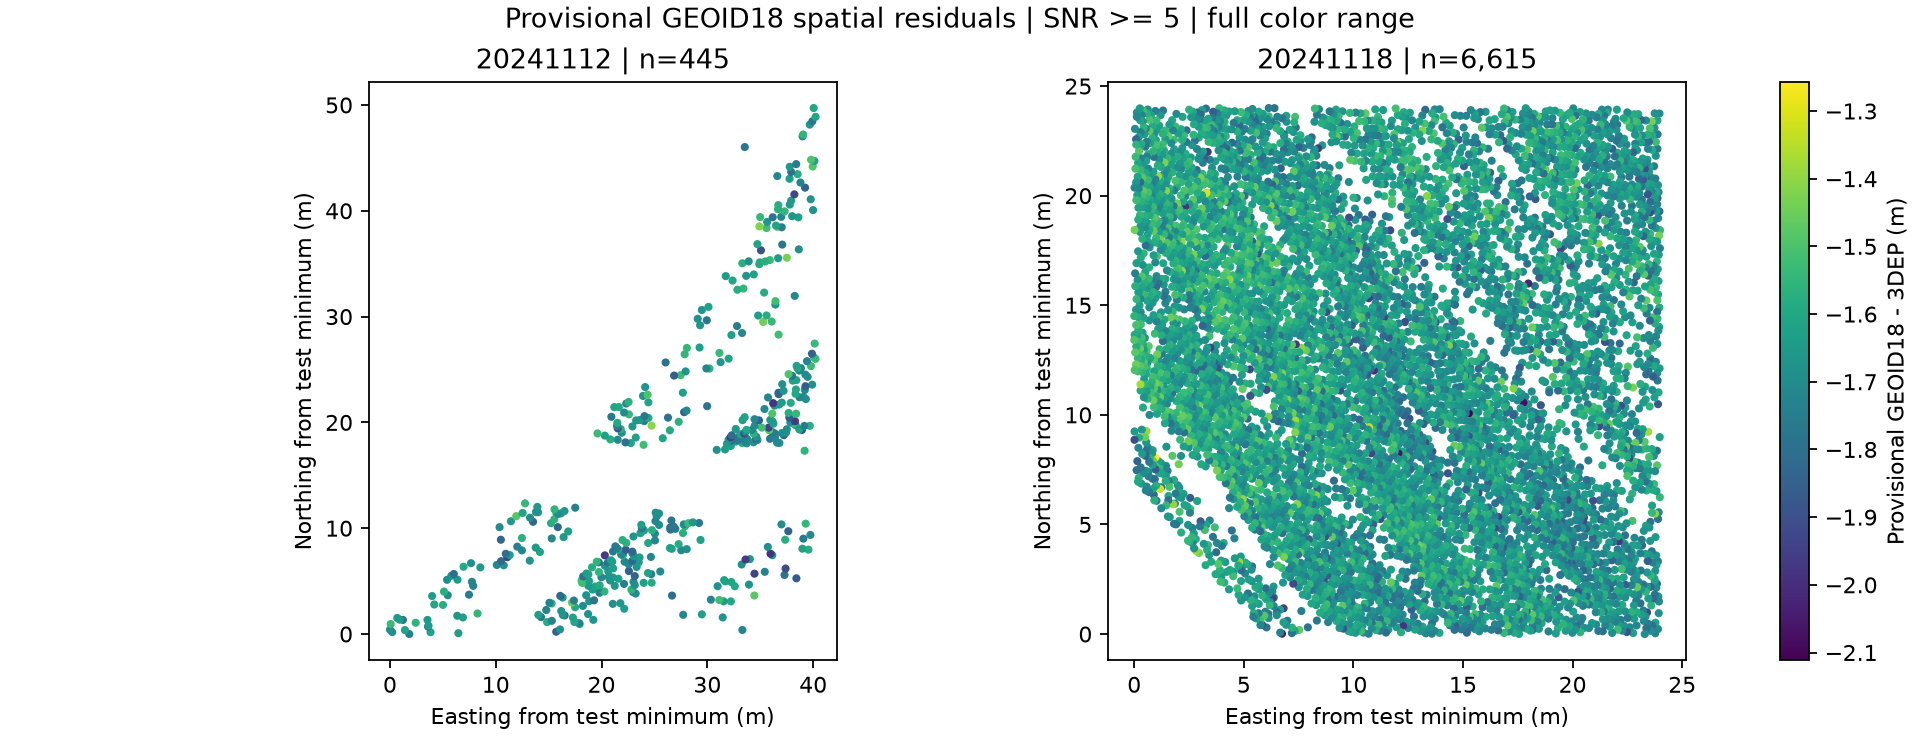

In [7]:
import matplotlib.pyplot as plt
for name, fig in plot_results(R):
    display(Image(filename=str(RUN_DIR / name)))
    plt.close(fig)

## 5. Numerical verification of the GEOID18 implementation (same-frame)

The fixed sample contains 20 real pulses per granule. IDs are frozen and rechecked using a deterministic max-min spatial sample over each complete H5 geolocation stream, finite Refh/coordinates, and CASALS-only SNR >= 5. No 3DEP height or residual is read during sample selection. The manifest records pulse ID, coordinates, Refh, SNR, selection rank, and the coordinate assumption.

For this numerical check only, each coordinate pair is **Assumed NAD83(2011) coordinates for numerical verification only**. This does not transform or identify the CASALS source frame. The checked operation is the existing audited C7/PROJ pipeline and pinned `us_noaa_g2018u0.tif` grid. Independent rasterio bilinear interpolation uses the existing four-cell pixel-center check. NGS requests explicitly send `lat`, negative-west `lon`, and `model=14`; a response is accepted only when it identifies GEOID18 and metres. Requests are sequential. Complete request parameters, UTC request times, HTTP status, raw response, and validation status are saved under the current timestamped run.

The VDatum Full API receives explicit geographic coordinates and heights in metres, NAD83_2011 ellipsoidal source and horizontal frames, NAVD88 target height with GEOID18, the documented region for each granule, and input/output epoch 2010.0. This is a same-frame software comparison under an assumed input. The API does not establish the unknown CASALS realization or coordinate epoch. Valid previous responses with identical requests may be reused and are identified in the request log. Service failures remain failures; local results are retained.

The geoid differences are `N_PROJ - N_NGS`, `N_RASTER - N_NGS`, and `N_PROJ - N_RASTER`. Transformation comparisons include `H_PROJ - H_VDATUM` and `H_VDATUM - H_NGS`. These numerical software differences are separate from the existing CASALS-3DEP residual.


**Scope:** because the input is the assumed NAD83(2011) coordinate, this section verifies the GEOID18 grid implementation only. NGS, VDatum, PROJ and the raster check all read the same GEOID18 model, so their agreement shows implementation consistency, not independent validation of the frame step. The frame step is verified in Section 3c.

**Table 1 - GEOID18 model verification; metres**

,granule_id,verification_points,successful_NGS_calls,PROJ_vs_NGS_mean_m,PROJ_vs_NGS_median_m,PROJ_vs_NGS_rmse_m,PROJ_vs_NGS_max_abs_m,Raster_vs_NGS_mean_m,Raster_vs_NGS_median_m,Raster_vs_NGS_rmse_m,Raster_vs_NGS_max_abs_m,PROJ_vs_Raster_mean_m,PROJ_vs_Raster_median_m,PROJ_vs_Raster_rmse_m,PROJ_vs_Raster_max_abs_m,tolerance_m,status
0,casals_l1b_20241112T165718_001_02,20,20,-0.000082,-0.000070,0.000279,0.000609,-0.000082,-0.000071,0.000278,0.000610,6.753195e-09,1.015007e-07,0.000002,0.000004,0.01,PASSED
1,casals_l1b_20241118T171757_001_02,20,20,-0.000081,-0.000098,0.000264,0.000450,-0.000082,-0.000097,0.000264,0.000448,6.281084e-07,4.796645e-07,0.000002,0.000005,0.01,PASSED


**Table 2 - Same-frame vertical transformation verification; metres**

,granule_id,successful_VDatum_calls,PROJ_minus_VDatum_mean_m,PROJ_minus_VDatum_median_m,PROJ_minus_VDatum_RMSE_m,PROJ_minus_VDatum_max_abs_m,VDatum_minus_NGS_max_abs_m,model,epoch_assumption,tolerance_m,status
0,casals_l1b_20241112T165718_001_02,20,-0.000011,-0.000011,0.000515,0.001101,0.000497,NAD83(2011) ellipsoid to NAVD88 using GEOID18,2010.0 input and output for same-frame numeric...,0.01,PASSED
1,casals_l1b_20241118T171757_001_02,20,-0.000003,0.000043,0.000337,0.000625,0.000722,NAD83(2011) ellipsoid to NAVD88 using GEOID18,2010.0 input and output for same-frame numeric...,0.01,PASSED


**Does PROJ compute GEOID18 correctly?** Under the explicitly assumed NAD83(2011) coordinates, the numerical result is compared against both an independent rasterio interpolation and NOAA NGS GEOID18 service output:
- 20241112: 20 fixed pulses; PROJ–NGS max |ΔN| 0.0006091331337714223 m; raster–NGS max |ΔN| 0.0006097717285129534 m; PROJ–raster max |ΔN| 3.935185560521859e-06 m; NGS calls 20/20 (PASSED).
- 20241118: 20 fixed pulses; PROJ–NGS max |ΔN| 0.0004501403272740845 m; raster–NGS max |ΔN| 0.0004478149414097743 m; PROJ–raster max |ΔN| 4.935297567953967e-06 m; NGS calls 20/20 (PASSED).

**Does NOAA VDatum agree under the same frame assumption?**
- 20241112: VDatum calls 20/20; PROJ–VDatum mean -1.0670512126687015e-05 m, RMSE 0.0005148097795705779 m, maximum absolute difference 0.0011014476991419997 m (PASSED; NAD83(2011) ellipsoid to NAVD88 using GEOID18; epoch 2010.0 in/out).
- 20241118: VDatum calls 20/20; PROJ–VDatum mean -2.9014507976210524e-06 m, RMSE 0.0003373598910549753 m, maximum absolute difference 0.0006247133114243297 m (PASSED; NAD83(2011) ellipsoid to NAVD88 using GEOID18; epoch 2010.0 in/out).

**Can software differences explain a CASALS–3DEP residual?** These comparisons quantify numerical model and conversion implementations only. They do not use 3DEP values to choose samples, methods, or parameters. The independent 3DEP residual is reported separately in the following evaluation section.

**What remains unresolved?** The API comparison assigns the same numeric coordinates to NAD83(2011), epoch 2010.0 for verification. CASALS WGS84 realization, coordinate epoch, and any upstream frame conversion remain unknown; the installed WGS84-ensemble-to-NAD83(2011) step remains a no-op. The software agreement therefore does not prove a CASALS source-frame conversion or strict vertical closure. No additional physical correction is applied.

**Classification:** Software numerical verification **PASSED**; source-frame transformation verification **UNRESOLVED**; strict CASALS–3DEP vertical closure **NOT ACHIEVED**.

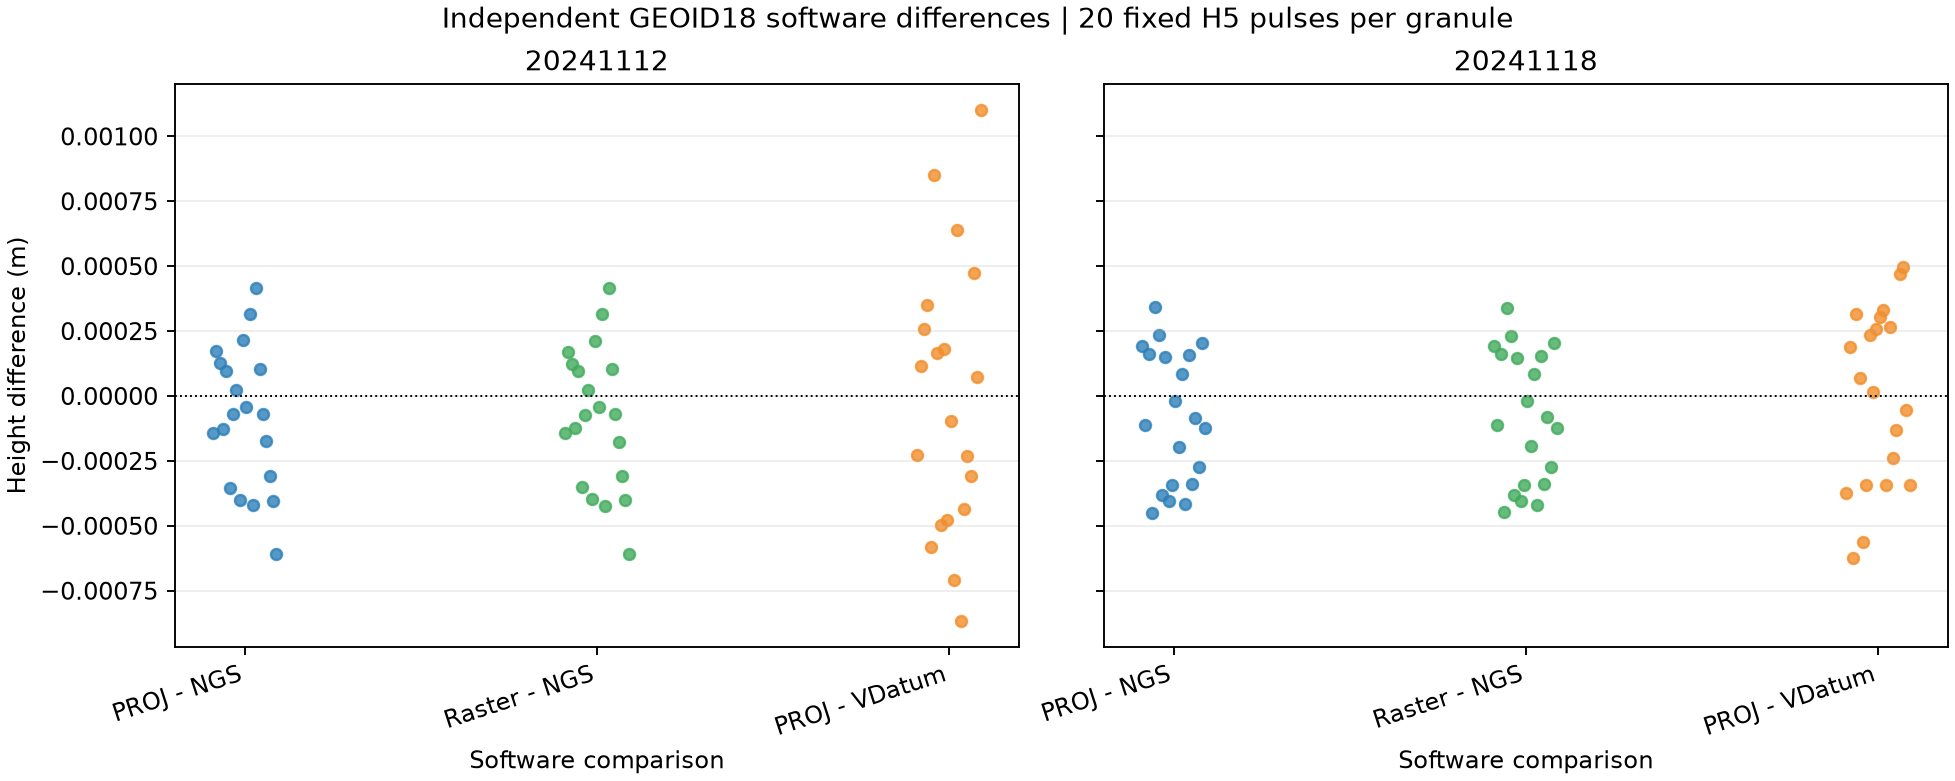

**Separate independent 3DEP context - existing H0 C7 test population; not an input to software verification**

,granule_id,n,eligible_n,coverage,mean_bias_m,RMSE_m,NMAD_m
8,casals_l1b_20241112T165718_001_02,445,478,0.931,-1.6705,1.6735,0.0877
26,casals_l1b_20241118T171757_001_02,6615,6615,1.000,-1.6486,1.6510,0.0874


**Interpretation against the independent 3DEP result.** Across both granules, the largest sampled software difference is 0.001101 m, so the GEOID18 numerical implementation cannot account for any metre-level CASALS-3DEP residual. This same-frame agreement does not validate the WGS84-to-NAD83(2011) frame conversion; see Section 3c.

**Separate HTDP-propagated checkpoints.** Status `PASSED` for two fixed pulse-0 points; this verifies only the conditional ITRF2014 assumption and the numerical vertical route.

In [8]:
import numpy as np
from research.reference.geodetic_crosscheck import run_geodetic_crosscheck
X = run_geodetic_crosscheck(RUN_DIR / 'geodetic_crosscheck', project_root=ROOT)
display(Markdown('**Table 1 - GEOID18 model verification; metres**'))
display(X['geoid_summary'])
display(Markdown('**Table 2 - Same-frame vertical transformation verification; metres**'))
display(X['vdatum_summary'])
display(Markdown(X['interpretation']))
display(Image(filename=str(X['output'] / 'software_differences.png')))
display(Markdown('**Separate independent 3DEP context - existing H0 C7 test population; not an input to software verification**'))
c7_context = R['final_summary'][['granule_id', 'n', 'eligible_n', 'coverage', 'mean_bias_m', 'RMSE_m', 'NMAD_m']].copy()
display(c7_context.round(4))
software_values = [
    X['geoid_comparison'][['PROJ_minus_NGS_m', 'Raster_minus_NGS_m', 'PROJ_minus_Raster_m']].abs().to_numpy().ravel(),
    X['vdatum_comparison'][['PROJ_minus_VDatum_m', 'VDatum_minus_NGS_height_m']].abs().to_numpy().ravel(),
]
software_values = [v[np.isfinite(v)] for v in software_values]
software_max_m = max((float(v.max()) for v in software_values if len(v)), default=float('nan'))
if X['summary']['software_numerical_verification'] == 'PASSED':
    conclusion = (f"Across both granules, the largest sampled software difference is {software_max_m:.6f} m, so the GEOID18 "
                  "numerical implementation cannot account for any metre-level CASALS-3DEP residual. "
                  "This same-frame agreement does not validate the WGS84-to-NAD83(2011) frame conversion; see Section 3c.")
else:
    conclusion = (f"External same-frame software verification is {X['summary']['software_numerical_verification']}; "
                  f"the largest available numerical difference is {software_max_m:.6f} m. "
                  "Unavailable comparisons remain unresolved.")
display(Markdown('**Interpretation against the independent 3DEP result.** ' + conclusion))
if XT is not None:
    display(Markdown('**Separate HTDP-propagated checkpoints.** Status `' + XT['status']['status'] +
        '` for two fixed pulse-0 points; this verifies only the conditional ITRF2014 assumption and the numerical vertical route.'))


## 6. CASALS versus independent 3DEP

`residual = CASALS_transformed_height - 3DEP_height`, in metres. CASALS heights are calculated using only four H5 inputs plus official geodetic models. Only afterward are 3DEP class-2 reference surfaces queried and evaluation residuals calculated; reference values cannot feed back into heights.

The fixed historical field and road pulse sets are unchanged. Primary reporting uses supported, low-slope field test ROIs at SNR >= 5; SNR >= 3 and all-valid strata retain every tail. Legacy split labels are membership evidence only and do not trigger parameter estimation. Coverage denominator is all fixed test-ROI pulses in the stratum before reference support rejection. Field seasonal cover remains uncertain; SNR does not classify a return as ground. Reviewed road interiors are a separate conditional check.

The original 0.75 m class-2 grid, every-10,000th-record holdout, robust local plane, >=6 neighbors within 3 m, <=5 degree slope, and <=0.20 m plane-residual NMAD are reused. Every method uses exactly the same pulse IDs and recomputed C7 reference heights. The signed bias remains reported: `RMSE**2 = mean_bias**2 + centered_RMSE**2`; centered dispersion is not absolute accuracy. No CASALS residual is removed by magnitude.

In [9]:
metric_columns = ['granule_id', 'stratum', 'method', 'eligible_n', 'n', 'coverage',
    'mean_bias_m', 'median_bias_m', 'RMSE_m', 'cRMSE_m', 'NMAD_m', 'absolute_P95_m']
display(R['metrics'].query("population == 'field'")[metric_columns].round(4))
display(Markdown('**Reviewed road independent-test check; separate population**'))
display(R['metrics'].query("population == 'road'")[metric_columns].round(4))

,granule_id,stratum,method,eligible_n,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
0,casals_l1b_20241112T165718_001_02,all_valid_refh,Native,17171,14885,0.8669,-13.4546,-37.5635,81.8953,80.7826,0.2954,180.3539
1,casals_l1b_20241112T165718_001_02,all_valid_refh,EGM2008,17171,14885,0.8669,23.3833,-0.7257,84.0987,80.7825,0.2957,208.3507
2,casals_l1b_20241112T165718_001_02,all_valid_refh,GEOID18,17171,14885,0.8669,22.4477,-1.6613,83.8434,80.7825,0.2957,207.4152
3,casals_l1b_20241112T165718_001_02,snr_ge_3,Native,4852,4274,0.8809,-37.3889,-37.5820,38.3468,8.5174,0.1174,37.8136
4,casals_l1b_20241112T165718_001_02,snr_ge_3,EGM2008,4852,4274,0.8809,-0.5510,-0.7440,8.5352,8.5174,0.1173,0.9791
5,casals_l1b_20241112T165718_001_02,snr_ge_3,GEOID18,4852,4274,0.8809,-1.4866,-1.6796,8.6462,8.5174,0.1173,1.9147
6,casals_l1b_20241112T165718_001_02,snr_ge_5,Native,478,445,0.9310,-37.5729,-37.5633,37.5730,0.1005,0.0876,37.7529
7,casals_l1b_20241112T165718_001_02,snr_ge_5,EGM2008,478,445,0.9310,-0.7349,-0.7252,0.7417,0.1005,0.0877,0.9151
8,casals_l1b_20241112T165718_001_02,snr_ge_5,GEOID18,478,445,0.9310,-1.6705,-1.6609,1.6735,0.1005,0.0877,1.8507
18,casals_l1b_20241118T171757_001_02,all_valid_refh,Native,8924,8924,1.0000,-36.4329,-38.0194,41.1173,19.0599,0.0948,38.2131


**Reviewed road independent-test check; separate population**

,granule_id,stratum,method,eligible_n,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
9,casals_l1b_20241112T165718_001_02,all_valid_refh,Native,1131,147,0.1300,-4.9917,-37.6938,92.9330,92.7988,0.3181,186.4110
10,casals_l1b_20241112T165718_001_02,all_valid_refh,EGM2008,1131,147,0.1300,31.8425,-0.8595,98.1099,92.7988,0.3180,214.7503
11,casals_l1b_20241112T165718_001_02,all_valid_refh,GEOID18,1131,147,0.1300,30.9070,-1.7951,97.8103,92.7988,0.3180,213.8148
12,casals_l1b_20241112T165718_001_02,snr_ge_3,Native,453,54,0.1192,-36.1486,-37.7255,37.9431,11.5307,0.1265,37.9607
13,casals_l1b_20241112T165718_001_02,snr_ge_3,EGM2008,453,54,0.1192,0.6857,-0.8912,11.5510,11.5307,0.1265,1.1265
14,casals_l1b_20241112T165718_001_02,snr_ge_3,GEOID18,453,54,0.1192,-0.2499,-1.8268,11.5334,11.5307,0.1265,2.0620
15,casals_l1b_20241112T165718_001_02,snr_ge_5,Native,84,14,0.1667,-37.7221,-37.7364,37.7223,0.1014,0.0456,37.8482
16,casals_l1b_20241112T165718_001_02,snr_ge_5,EGM2008,84,14,0.1667,-0.8878,-0.9021,0.8936,0.1014,0.0456,1.0139
17,casals_l1b_20241112T165718_001_02,snr_ge_5,GEOID18,84,14,0.1667,-1.8234,-1.8377,1.8262,0.1014,0.0456,1.9494
27,casals_l1b_20241118T171757_001_02,all_valid_refh,Native,225,165,0.7333,-34.5253,-37.9497,40.1461,20.4868,0.1136,38.2345


### 6b. Primary result under the rigorous frame transformation

H2 (ITRF2014) is shown as the primary hypothesis because it is the only one with an independent geocentric XYZ checkpoint, HTDP check and VDatum check, not because of its residual; H1, H3 and H4 are reported alongside as a range and H0 (no frame change) as the comparison. Intervals are 95% moving-block bootstrap intervals (blocks of 5,000 consecutive pulse indices) for the mean bias, which accounts for along-track correlation. They cover sampling variability only, not the unresolved frame assumption or systematic terms. All values are evaluation only; no hypothesis is selected by its residual.

**Table 6b-1 - Field independent test, all SNR strata, H2 primary; H1-H4**

,granule_id,stratum,hypothesis,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
0,casals_l1b_20241112T165718_001_02,all_valid_refh,H0_noop_C7_baseline,14470,0.8427,22.7003,-1.6613,84.1738,81.0551,0.2972,207.6815
1,casals_l1b_20241112T165718_001_02,all_valid_refh,H1_WGS84_G2296_obs_epoch,14470,0.8427,24.0015,-0.3616,84.5336,81.0546,0.2976,208.9769
2,casals_l1b_20241112T165718_001_02,all_valid_refh,H2_ITRF2014_obs_epoch,14470,0.8427,24.0009,-0.3622,84.5334,81.0546,0.2977,208.9763
3,casals_l1b_20241112T165718_001_02,all_valid_refh,H3_ITRF2020_obs_epoch,14470,0.8427,24.0015,-0.3616,84.5336,81.0546,0.2976,208.9769
4,casals_l1b_20241112T165718_001_02,all_valid_refh,H4_ITRF2014_parameter_time_sensitivity_2010,14470,0.8427,24.0132,-0.3496,84.5370,81.0547,0.2971,208.9901
5,casals_l1b_20241112T165718_001_02,snr_ge_3,H0_noop_C7_baseline,4126,0.8504,-1.4772,-1.6802,8.7922,8.6672,0.1182,1.9175
6,casals_l1b_20241112T165718_001_02,snr_ge_3,H1_WGS84_G2296_obs_epoch,4126,0.8504,-0.1751,-0.3793,8.6686,8.6668,0.1207,0.6141
7,casals_l1b_20241112T165718_001_02,snr_ge_3,H2_ITRF2014_obs_epoch,4126,0.8504,-0.1757,-0.3799,8.6686,8.6668,0.1205,0.6148
8,casals_l1b_20241112T165718_001_02,snr_ge_3,H3_ITRF2020_obs_epoch,4126,0.8504,-0.1751,-0.3793,8.6686,8.6668,0.1207,0.6142
9,casals_l1b_20241112T165718_001_02,snr_ge_3,H4_ITRF2014_parameter_time_sensitivity_2010,4126,0.8504,-0.1635,-0.3669,8.6684,8.6668,0.1205,0.6025


**Table 6b-2 - Road reviewed-interior check (separate population), H2**

,granule_id,stratum,hypothesis,n,coverage,mean_bias_m,median_bias_m,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m
0,casals_l1b_20241112T165718_001_02,all_valid_refh,H2_ITRF2014_obs_epoch,8,0.0071,27.0483,-0.7413,68.5225,62.9581,0.5997,140.1373
1,casals_l1b_20241112T165718_001_02,snr_ge_3,H2_ITRF2014_obs_epoch,1,0.0022,-0.6820,-0.6820,0.6820,0.0000,0.0000,0.6820
2,casals_l1b_20241112T165718_001_02,snr_ge_5,H2_ITRF2014_obs_epoch,0,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
3,casals_l1b_20241118T171757_001_02,all_valid_refh,H2_ITRF2014_obs_epoch,165,0.7333,3.1688,-0.2553,20.7313,20.4877,0.1134,0.7763
4,casals_l1b_20241118T171757_001_02,snr_ge_3,H2_ITRF2014_obs_epoch,138,0.7077,-0.2706,-0.2577,0.2932,0.1130,0.1103,0.4734
5,casals_l1b_20241118T171757_001_02,snr_ge_5,H2_ITRF2014_obs_epoch,70,0.5983,-0.2504,-0.2314,0.2736,0.1101,0.1047,0.4693


**Table 6b-3 - Mean bias with 95% block-bootstrap interval, field, SNR >= 5**

,granule_id,hypothesis,n,n_blocks,mean_bias_m,ci95_low_m,ci95_high_m
0,casals_l1b_20241112T165718_001_02,H1_WGS84_G2296_obs_epoch,435,14,-0.3689,-0.3830,-0.3499
1,casals_l1b_20241118T171757_001_02,H1_WGS84_G2296_obs_epoch,6615,8,-0.2893,-0.3017,-0.2748
2,casals_l1b_20241112T165718_001_02,H2_ITRF2014_obs_epoch,435,14,-0.3695,-0.3836,-0.3505
3,casals_l1b_20241118T171757_001_02,H2_ITRF2014_obs_epoch,6615,8,-0.2899,-0.3023,-0.2754
4,casals_l1b_20241112T165718_001_02,H3_ITRF2020_obs_epoch,435,14,-0.3690,-0.3830,-0.3499
5,casals_l1b_20241118T171757_001_02,H3_ITRF2020_obs_epoch,6615,8,-0.2893,-0.3018,-0.2748
6,casals_l1b_20241112T165718_001_02,H4_ITRF2014_parameter_time_sensitivity_2010,437,14,-0.3577,-0.3713,-0.3395
7,casals_l1b_20241118T171757_001_02,H4_ITRF2014_parameter_time_sensitivity_2010,6615,8,-0.2821,-0.2949,-0.2674


#### H0/H2 signed residual histograms: vertical_residual_histograms.png (density normalized)

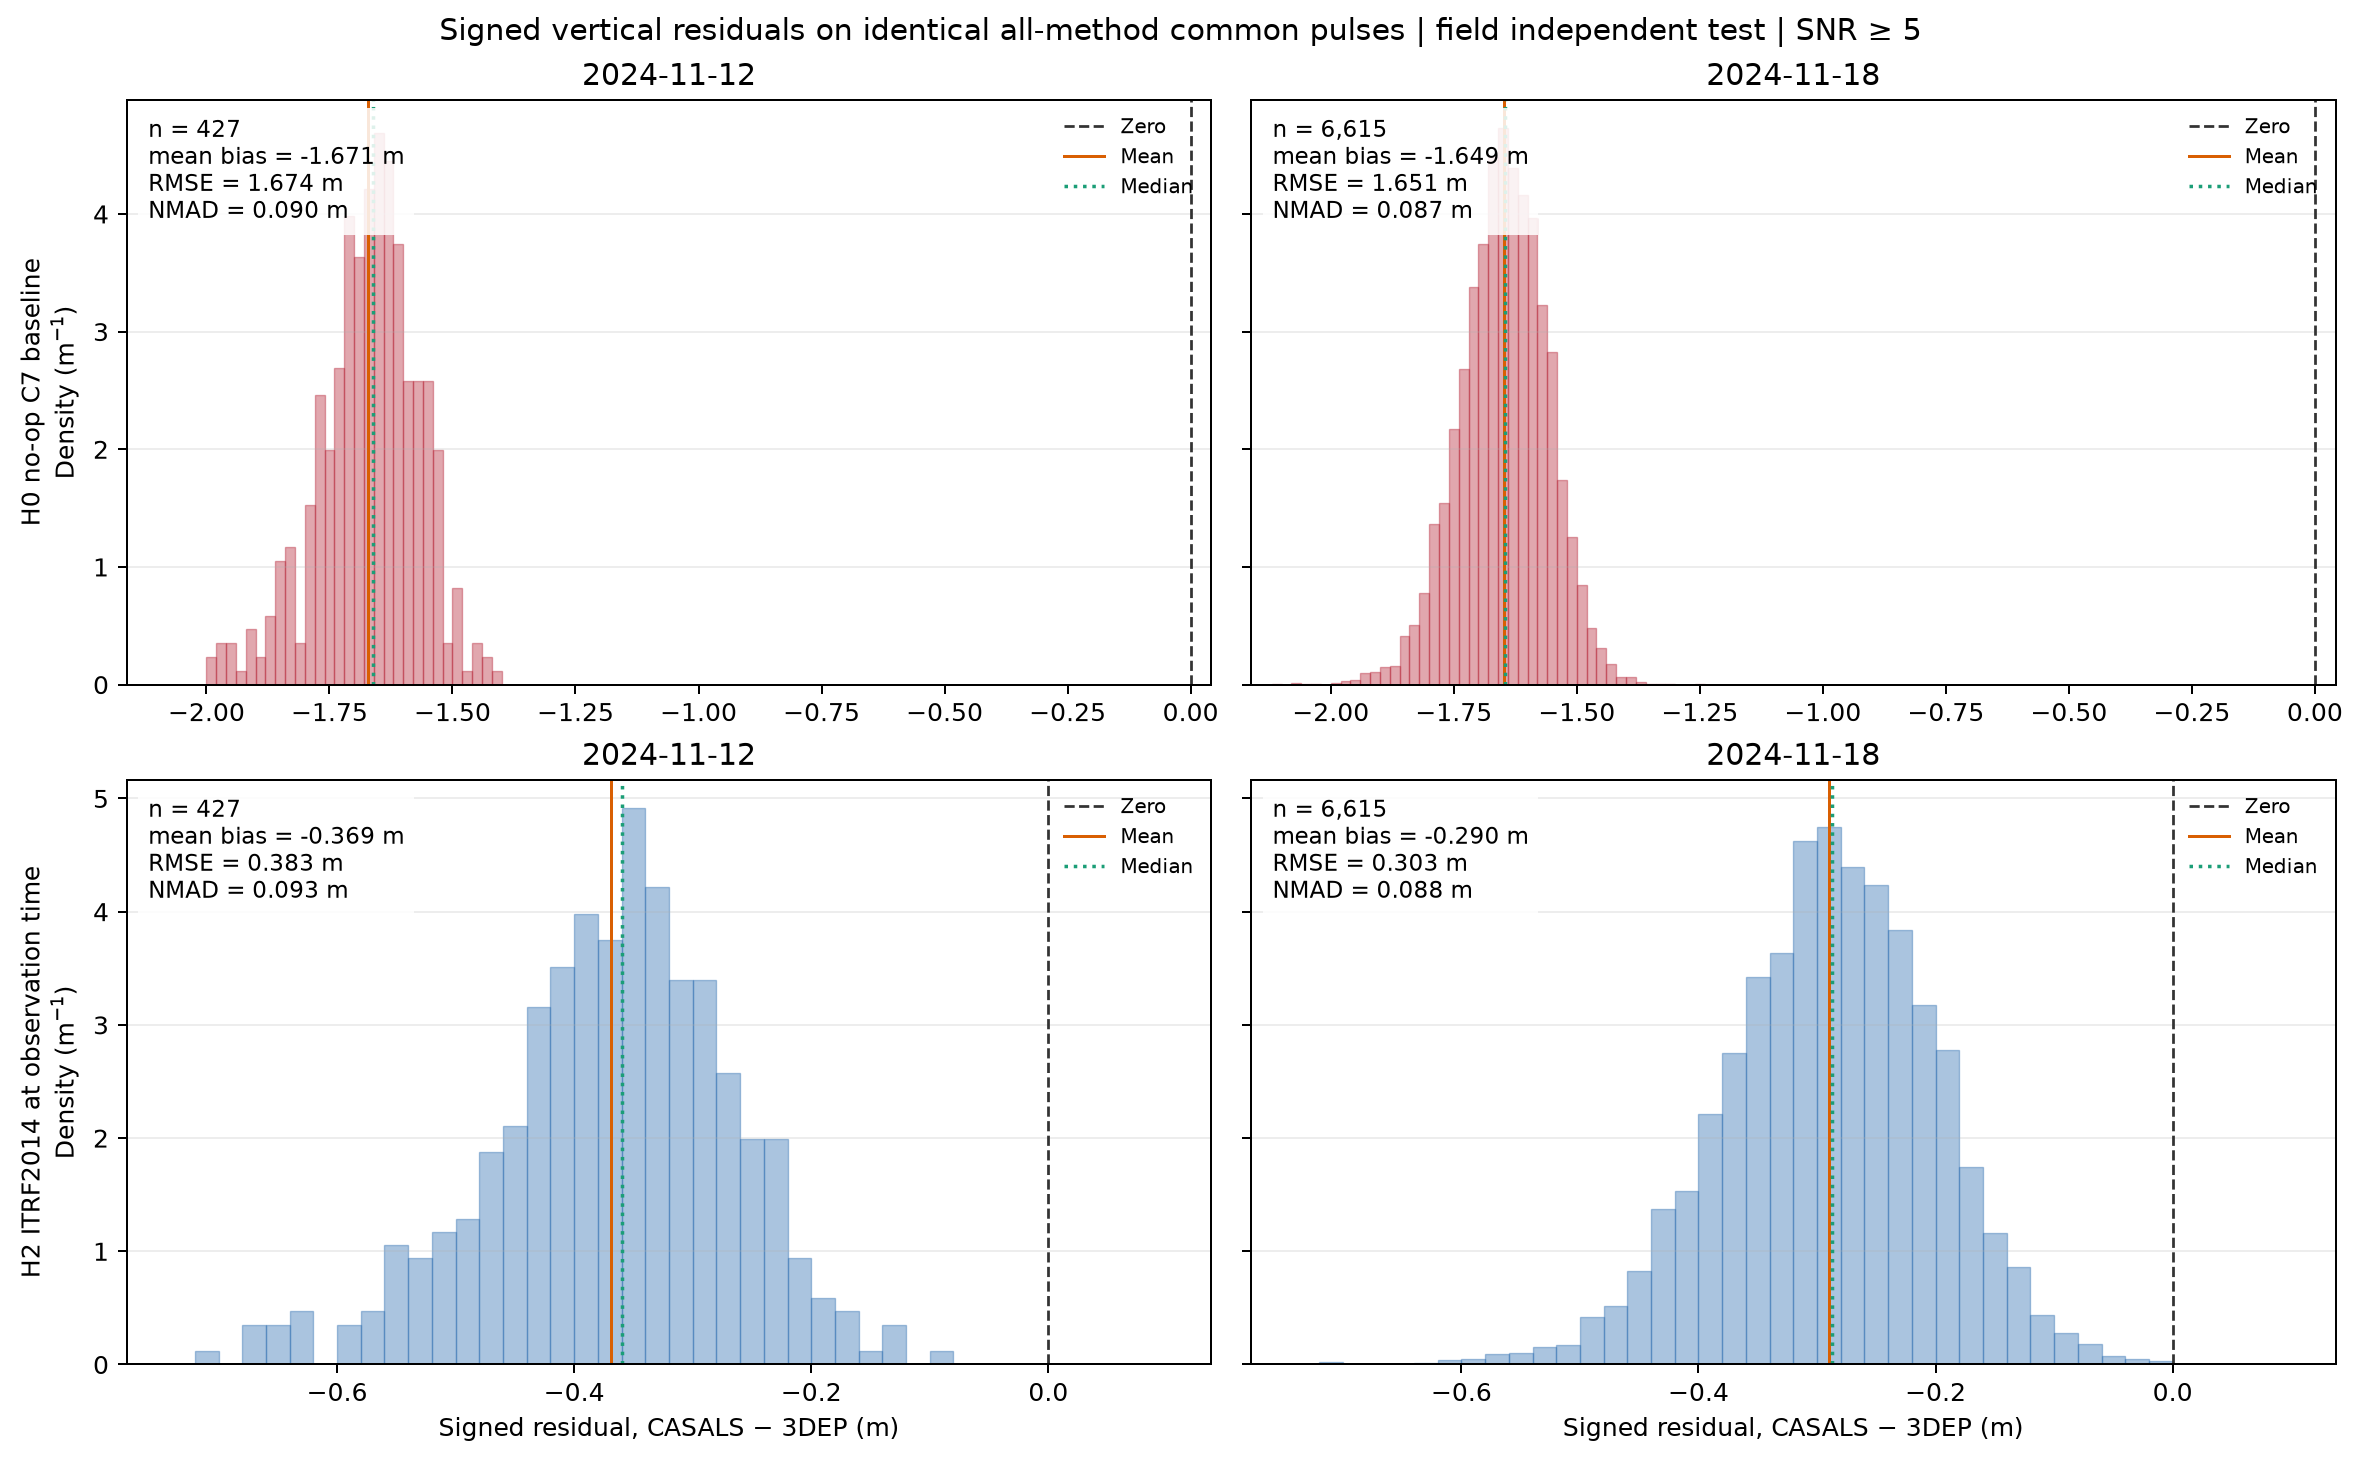

#### H0/H2 empirical CDF: h0_vs_h2_residual_cdf.png (uncentered signed residuals)

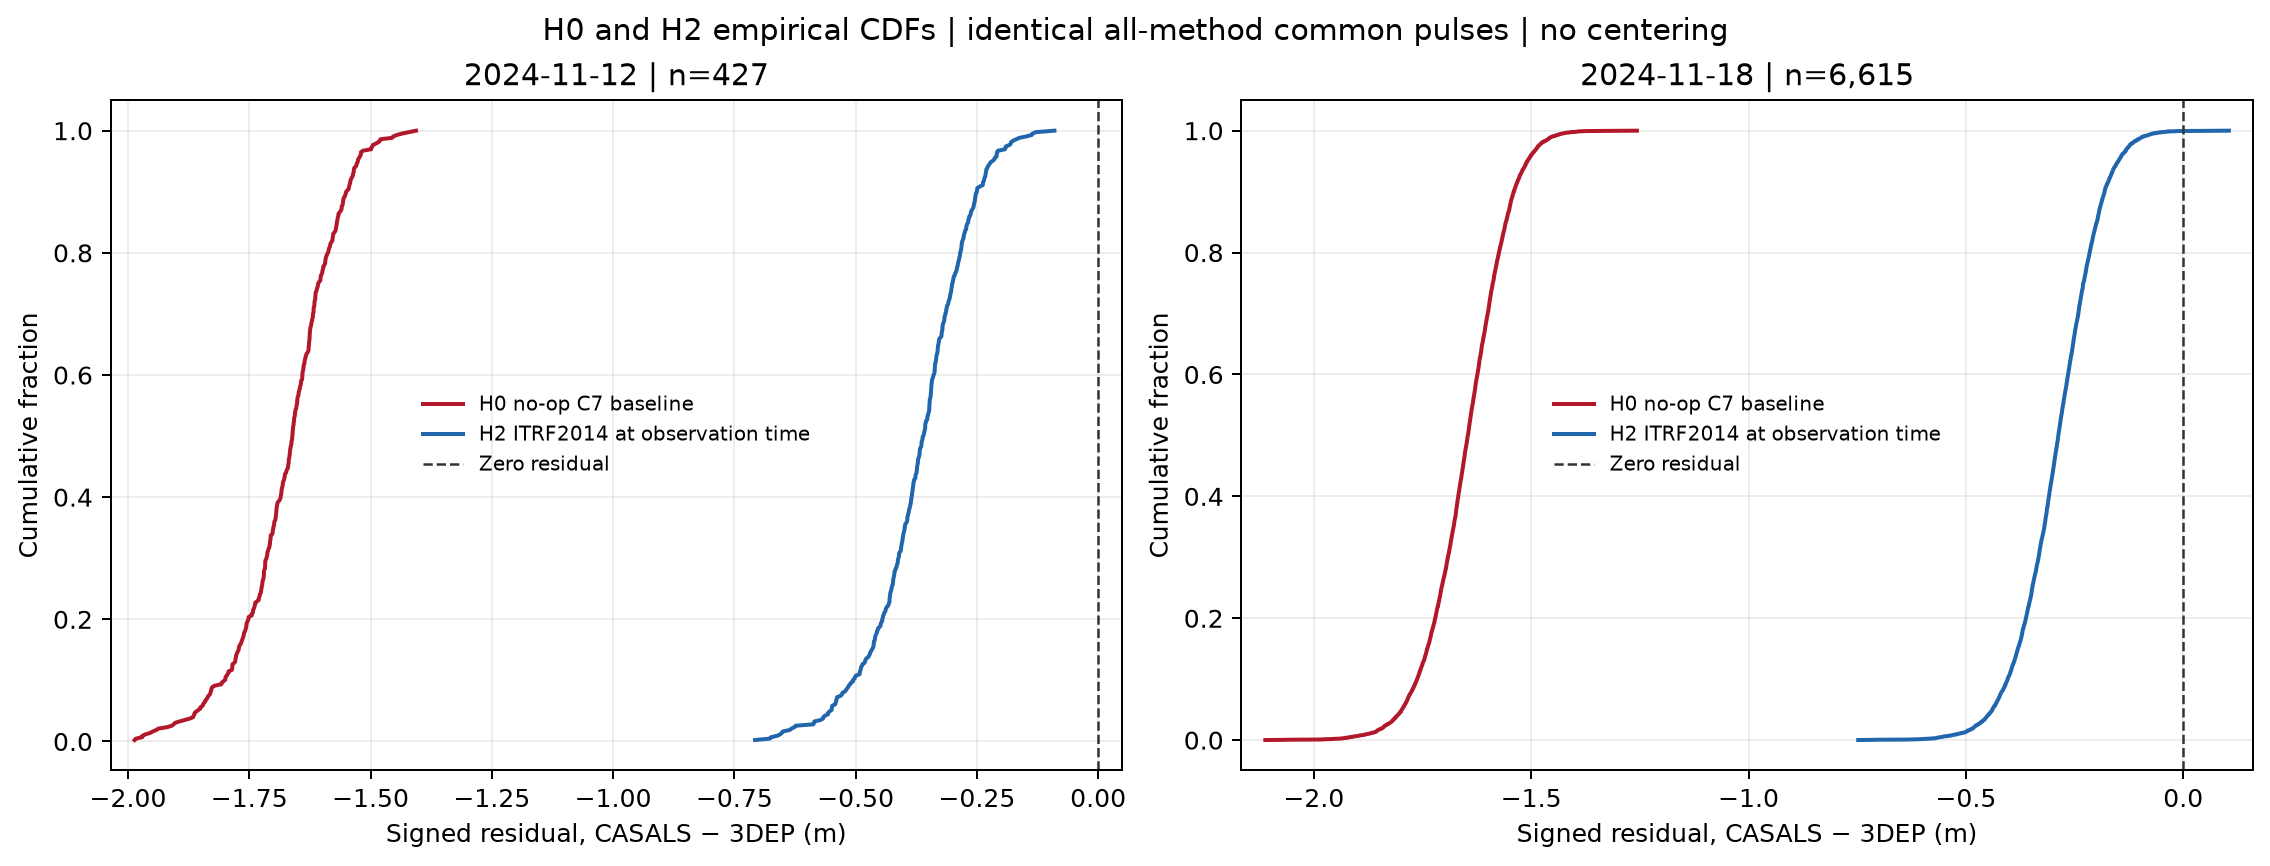

#### H2 spatial residuals: h2_spatial_residuals.png (H2 transformed EPSG:6347 coordinates)

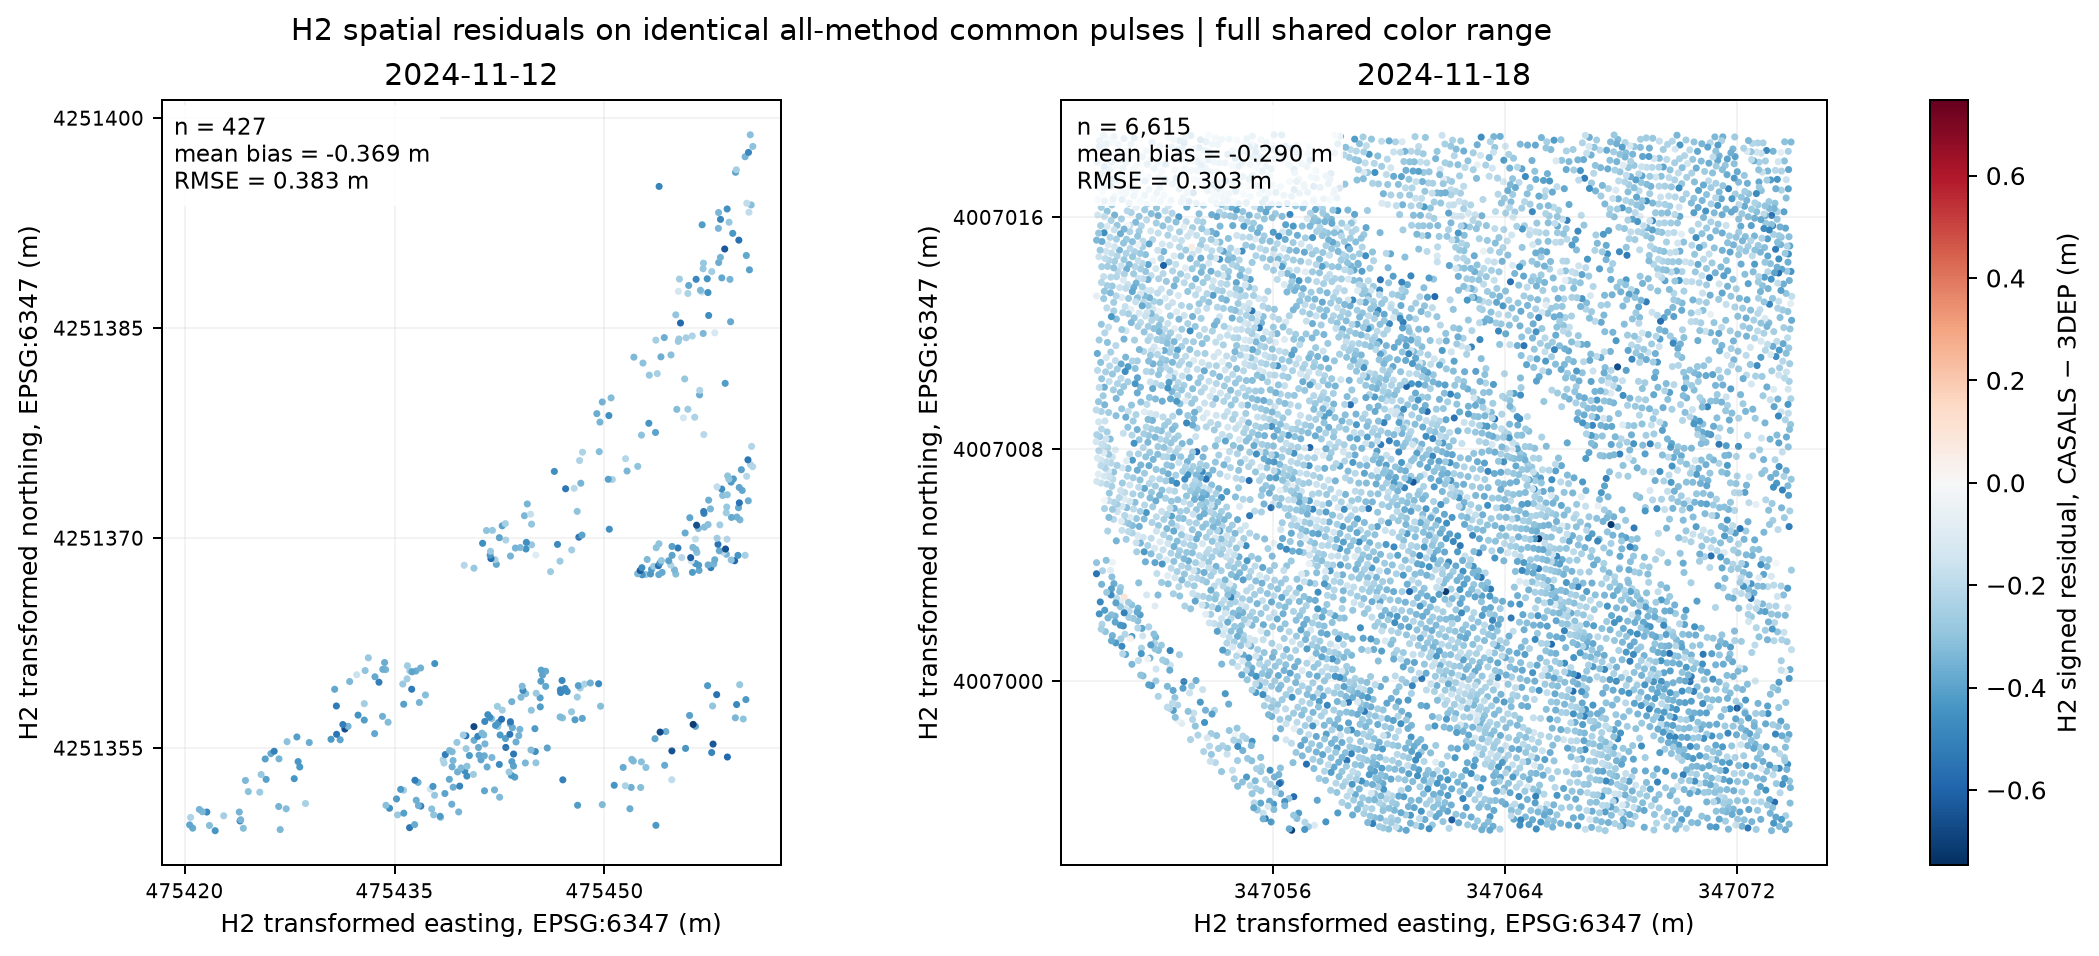

In [10]:
PRIMARY = 'H2_ITRF2014_obs_epoch'
hyp_all = F['metrics']
primary = hyp_all.query("population == 'field'")
cols = ['granule_id', 'stratum', 'hypothesis', 'n', 'coverage', 'mean_bias_m', 'median_bias_m', 'RMSE_m', 'cRMSE_m', 'NMAD_m', 'absolute_P95_m']
display(Markdown('**Table 6b-1 - Field independent test, all SNR strata, H2 primary; H1-H4**'))
display(primary[cols].round(4).reset_index(drop=True))
display(Markdown('**Table 6b-2 - Road reviewed-interior check (separate population), H2**'))
display(hyp_all.query("population == 'road' and hypothesis == 'H2_ITRF2014_obs_epoch'")[cols].round(4).reset_index(drop=True))
ci = pd.concat([block_bootstrap_bias(F['pulse_residuals'], hypothesis=h) for h in F['pulse_residuals'].hypothesis.unique() if not h.startswith('H0')])
display(Markdown('**Table 6b-3 - Mean bias with 95% block-bootstrap interval, field, SNR >= 5**'))
display(ci.round(4).reset_index(drop=True))
from research.reference.vertical_residual_plots import save_vertical_residual_plots
PLOT_PATHS = save_vertical_residual_plots(F, F['output'])
display(Markdown('#### H0/H2 signed residual histograms: vertical_residual_histograms.png (density normalized)'))
display(Image(filename=str(PLOT_PATHS['histograms'])))
display(Markdown('#### H0/H2 empirical CDF: h0_vs_h2_residual_cdf.png (uncentered signed residuals)'))
display(Image(filename=str(PLOT_PATHS['cdf'])))
display(Markdown('#### H2 spatial residuals: h2_spatial_residuals.png (H2 transformed EPSG:6347 coordinates)'))
display(Image(filename=str(PLOT_PATHS['spatial'])))

### 6c. Diagnostic: remaining bias versus stored tide terms (not applied)

The two granules have different `tide_earth` medians. The table shows what the H2 bias would be if that field were added to or subtracted from Refh. This is a **diagnostic hypothesis test that is not applied**: the field's sign, units and applied state are unverified, and two granules cannot validate a relationship. It only identifies what additional granules and processor documentation should test.

In [11]:
te = audit.query("field == 'tide_earth'").set_index('granule_id').median_numeric
h1 = ci.query("hypothesis == 'H2_ITRF2014_obs_epoch'").set_index('granule_id').mean_bias_m
diag = pd.DataFrame({'tide_earth_median': te, 'H2_bias_as_is': h1, 'if_tide_added': h1 + te, 'if_tide_subtracted': h1 - te})
display(diag.round(4))
display(Markdown('Granule-to-granule bias difference: as is %.3f m; tide added %.3f m; tide subtracted %.3f m. Two granules only: **not applied, not a finding**.' % tuple(abs(float(diag[c].iloc[0]-diag[c].iloc[1])) for c in ['H2_bias_as_is','if_tide_added','if_tide_subtracted'])))

,tide_earth_median,H2_bias_as_is,if_tide_added,if_tide_subtracted
granule_id,,,,
casals_l1b_20241112T165718_001_02,-0.0157,-0.3695,-0.3853,-0.3538
casals_l1b_20241118T171757_001_02,-0.0750,-0.2899,-0.3649,-0.2148


Granule-to-granule bias difference: as is 0.080 m; tide added 0.020 m; tide subtracted 0.139 m. Two granules only: **not applied, not a finding**.

## 7. Closure assessment

The earlier no-op run left metre-scale negative CASALS-minus-3DEP residuals. The new 3D routes show whether an omitted frame transformation is a **plausible major contributor under an ITRF-aligned source assumption**; the common-sample metrics and paired decomposition above quantify the height and query-position effects. This is numerical evidence conditional on the source frame. It does not establish which CRS describes the stored CASALS coordinates.

**Strict CASALS-3DEP height closure is not established.** The H5 flight time is not a coordinate-epoch record. PROJ's Helmert parameter epoch is not a propagation target, and H4 is only a parameter-time sensitivity. HTDP separately demonstrates a modelled ITRF2014-assumption propagation for two fixed points, but that does not verify the source frame of either full granule. The remaining residual, independent 3DEP accuracy, seasonal cover, and unresolved Refh ranging/tide application state remain separate evidence. No empirical offset or residual-selected frame is used.

Required physical evidence remains the per-granule GNSS/INS realization and coordinate epoch, the navigation-to-Refh processing chain, and the Refh time-to-range equation with field-level units, signs, stages, and applied/not-applied records.


In [12]:
final = ci.query("hypothesis == 'H2_ITRF2014_obs_epoch'").merge(
    F['metrics'].query("population == 'field' and stratum == 'snr_ge_5' and hypothesis == 'H2_ITRF2014_obs_epoch'")[['granule_id', 'coverage', 'RMSE_m', 'cRMSE_m', 'NMAD_m', 'absolute_P95_m']], on='granule_id')
rng = ci.groupby('granule_id').mean_bias_m.agg(['min', 'max'])
final['bias_range_hypotheses_m'] = [f"{rng.loc[g,'min']:+.3f} to {rng.loc[g,'max']:+.3f}" for g in final.granule_id]
final['H0_bias_m'] = R['final_summary'].set_index('granule_id').mean_bias_m.reindex(final.granule_id).to_numpy()
final['strict_closure'] = False
display(final.round(4))
for row in final.itertuples():
    display(Markdown(f"**{row.granule_id[11:19]}:** H2 (ITRF2014 at flight time -> NAD83(2011) -> GEOID18; frame epoch not propagated), n={row.n:,}; signed bias {row.mean_bias_m:+.4f} m (95% block CI {row.ci95_low_m:+.3f} to {row.ci95_high_m:+.3f}), H2-H4 and H1 range {row.bias_range_hypotheses_m} m, RMSE {row.RMSE_m:.4f} m, centered RMSE {row.cRMSE_m:.4f} m, NMAD {row.NMAD_m:.4f} m. H0 (no frame change) bias was {row.H0_bias_m:+.4f} m. Strict closure: **not achieved**; source frame unverified; no residual-derived correction applied."))

,granule_id,hypothesis,n,n_blocks,mean_bias_m,ci95_low_m,ci95_high_m,coverage,RMSE_m,cRMSE_m,NMAD_m,absolute_P95_m,bias_range_hypotheses_m,H0_bias_m,strict_closure
0,casals_l1b_20241112T165718_001_02,H2_ITRF2014_obs_epoch,435,14,-0.3695,-0.3836,-0.3505,0.8933,0.3826,0.1020,0.0933,0.5494,-0.370 to -0.358,-1.6705,False
1,casals_l1b_20241118T171757_001_02,H2_ITRF2014_obs_epoch,6615,8,-0.2899,-0.3023,-0.2754,1.0000,0.3033,0.0893,0.0879,0.4391,-0.290 to -0.282,-1.6486,False


**20241112:** H2 (ITRF2014 at flight time -> NAD83(2011) -> GEOID18; frame epoch not propagated), n=435; signed bias -0.3695 m (95% block CI -0.384 to -0.351), H2-H4 and H1 range -0.370 to -0.358 m, RMSE 0.3826 m, centered RMSE 0.1020 m, NMAD 0.0933 m. H0 (no frame change) bias was -1.6705 m. Strict closure: **not achieved**; source frame unverified; no residual-derived correction applied.

**20241118:** H2 (ITRF2014 at flight time -> NAD83(2011) -> GEOID18; frame epoch not propagated), n=6,615; signed bias -0.2899 m (95% block CI -0.302 to -0.275), H2-H4 and H1 range -0.290 to -0.282 m, RMSE 0.3033 m, centered RMSE 0.0893 m, NMAD 0.0879 m. H0 (no frame change) bias was -1.6486 m. Strict closure: **not achieved**; source frame unverified; no residual-derived correction applied.